<a href="https://colab.research.google.com/github/asiaihsan/plant-disease-classifier/blob/main/Plant_Leaf_Disease_Image_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
path = kagglehub.dataset_download("arjuntejaswi/plant-village")
print(path)

Using Colab cache for faster access to the 'plant-village' dataset.
/kaggle/input/plant-village


In [2]:
import os

path = "/kaggle/input/plant-village"
for root, dirs, files in os.walk(path):
    if len(files) > 0:
        print(os.path.basename(root), "->", len(files), "images")

Pepper__bell___Bacterial_spot -> 997 images
Potato___healthy -> 152 images
Tomato_Leaf_Mold -> 952 images
Tomato__Tomato_YellowLeaf__Curl_Virus -> 3209 images
Tomato_Bacterial_spot -> 2127 images
Tomato_Septoria_leaf_spot -> 1771 images
Tomato_healthy -> 1591 images
Tomato_Spider_mites_Two_spotted_spider_mite -> 1676 images
Tomato_Early_blight -> 1000 images
Tomato__Target_Spot -> 1404 images
Pepper__bell___healthy -> 1478 images
Potato___Late_blight -> 1000 images
Tomato_Late_blight -> 1909 images
Potato___Early_blight -> 1000 images
Tomato__Tomato_mosaic_virus -> 373 images


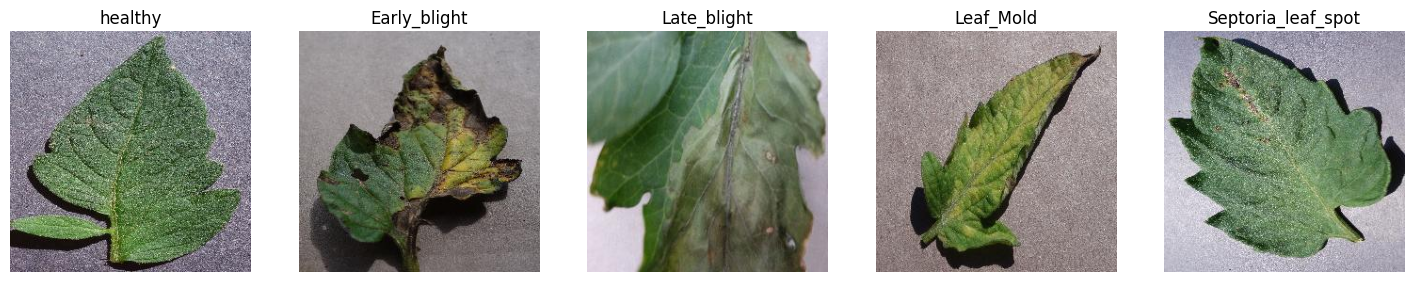

In [3]:
import os, random
import matplotlib.pyplot as plt
from PIL import Image

path = "/kaggle/input/plant-village"
classes = ["Tomato_healthy", "Tomato_Early_blight", "Tomato_Late_blight",
           "Tomato_Leaf_Mold", "Tomato_Septoria_leaf_spot"]

def find_folder(name):
    for root, dirs, files in os.walk(path):
        if os.path.basename(root) == name:
            return root

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, classes):
    folder = find_folder(c)
    img = Image.open(os.path.join(folder, random.choice(os.listdir(folder))))
    ax.imshow(img)
    ax.set_title(c.replace("Tomato_", ""))
    ax.axis("off")
plt.show()

In [4]:
import shutil
from pathlib import Path

random.seed(42)
out = Path("/content/data")

for c in classes:
    folder = find_folder(c)
    files = os.listdir(folder)
    random.shuffle(files)
    n = len(files)
    splits = {"train": files[:int(0.7*n)],
              "val": files[int(0.7*n):int(0.85*n)],
              "test": files[int(0.85*n):]}
    for s, fs in splits.items():
        (out/s/c).mkdir(parents=True, exist_ok=True)
        for f in fs:
            shutil.copy(os.path.join(folder, f), out/s/c/f)
    print(c, {s: len(fs) for s, fs in splits.items()})

Tomato_healthy {'train': 1113, 'val': 239, 'test': 239}
Tomato_Early_blight {'train': 700, 'val': 150, 'test': 150}
Tomato_Late_blight {'train': 1336, 'val': 286, 'test': 287}
Tomato_Leaf_Mold {'train': 666, 'val': 143, 'test': 143}
Tomato_Septoria_leaf_spot {'train': 1239, 'val': 266, 'test': 266}


In [5]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/data/train", image_size=IMG_SIZE, batch_size=BATCH, shuffle=True, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/data/val", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/data/test", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
print(class_names)

Found 5054 files belonging to 5 classes.
Found 1084 files belonging to 5 classes.
Found 1085 files belonging to 5 classes.
['Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_healthy']


In [6]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(5, activation="softmax")
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - accuracy: 0.5437 - loss: 1.1093 - val_accuracy: 0.7786 - val_loss: 0.5498
Epoch 2/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.8142 - loss: 0.4948 - val_accuracy: 0.8478 - val_loss: 0.4155
Epoch 3/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.8666 - loss: 0.3595 - val_accuracy: 0.8552 - val_loss: 0.4107
Epoch 4/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 204s 1s/step - accuracy: 0.9021 - loss: 0.2655 - val_accuracy: 0.8819 - val_loss: 0.3166
Epoch 5/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.9195 - loss: 0.2228 - val_accuracy: 0.8589 - val_loss: 0.4143
Epoch 6/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.9579 - loss: 0.1270 - val_accuracy: 0.8865 - val_loss: 0.3904
Epoch 7/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 201s 1s/step - accuracy: 0.9656 - loss: 0.0915 - val_accuracy: 0.8976 - val_loss: 0.3203
Epoch 8/10
158/158 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.9747 - loss: 0.0755 - val_accu

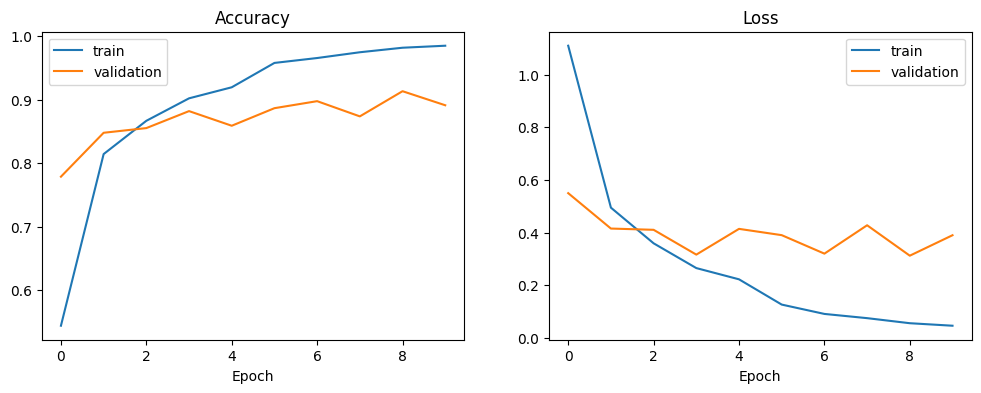

In [8]:
acc, val_acc = history.history["accuracy"], history.history["val_accuracy"]
loss, val_loss = history.history["loss"], history.history["val_loss"]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label="train")
plt.plot(val_acc, label="validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="train")
plt.plot(val_loss, label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

34/34 ━━━━━━━━━━━━━━━━━━━━ 15s 438ms/step - accuracy: 0.8922 - loss: 0.4318
Test accuracy: 0.8922
34/34 ━━━━━━━━━━━━━━━━━━━━ 10s 295ms/step
                           precision    recall  f1-score   support

      Tomato_Early_blight       0.83      0.81      0.82       150
       Tomato_Late_blight       0.90      0.87      0.88       287
         Tomato_Leaf_Mold       0.76      0.94      0.84       143
Tomato_Septoria_leaf_spot       0.93      0.86      0.89       266
           Tomato_healthy       0.98      0.97      0.98       239

                 accuracy                           0.89      1085
                macro avg       0.88      0.89      0.88      1085
             weighted avg       0.90      0.89      0.89      1085



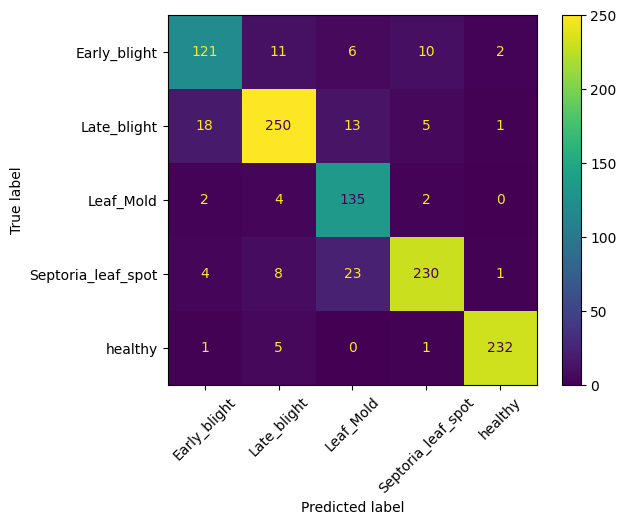

In [9]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=[c.replace("Tomato_", "") for c in class_names]).plot(xticks_rotation=45)
plt.show()

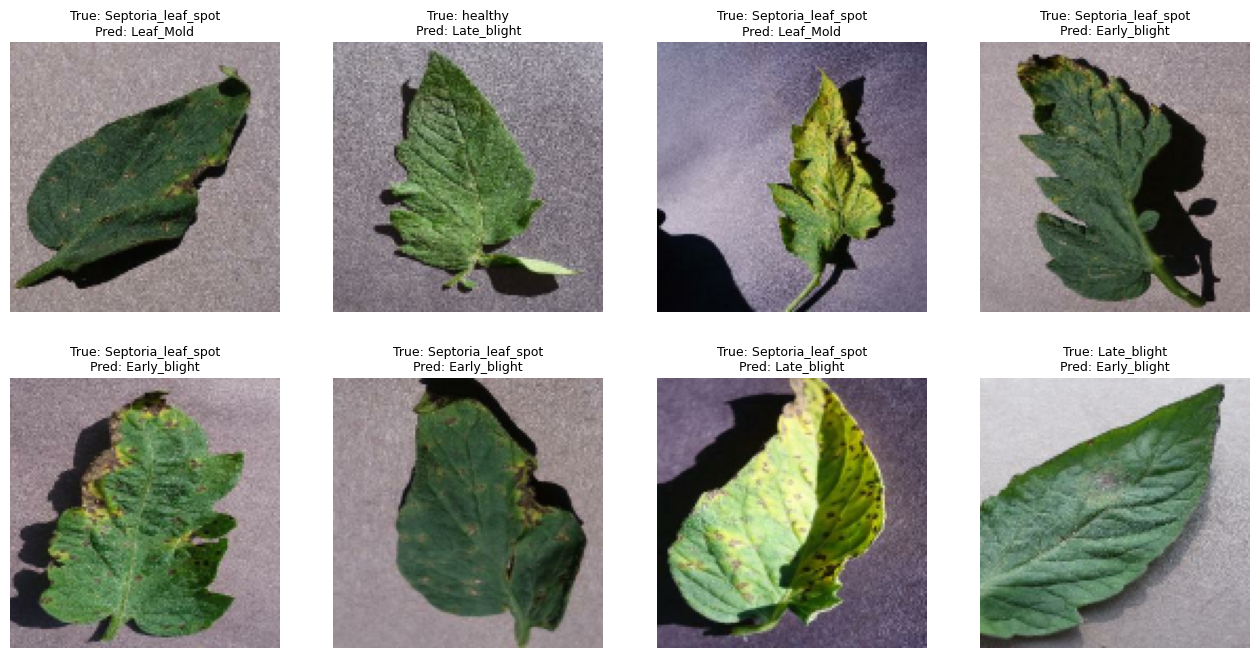

In [10]:
wrong = np.where(y_true != y_pred)[0]
images = np.concatenate([x.numpy() for x, y in test_ds])

plt.figure(figsize=(16, 8))
for i, idx in enumerate(random.sample(list(wrong), 8)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[idx].astype("uint8"))
    plt.title(f"True: {class_names[y_true[idx]].replace('Tomato_', '')}\nPred: {class_names[y_pred[idx]].replace('Tomato_', '')}",
              fontsize=9)
    plt.axis("off")
plt.show()